<a href="https://colab.research.google.com/github/Azizkhan-23/Supervised-Classification-Regression-Modeling-Tuning/blob/main/Supervised_Classification_Regression_Modeling_%26_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("customer-churn-training.csv")

print("Dataset loaded successfully!")
print(df.shape)
print(df.columns.tolist())

display(df.head())


Saving customer-churn-training.csv to customer-churn-training.csv
Dataset loaded successfully!
(12, 7)
['customer_id', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type', 'churned']


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0


In [ ]:

from sklearn.model_selection import train_test_split

# Automatically find the target column
candidates = [
    col for col in df.columns
    if col.strip().lower() in [
        "churn", "churned", "exited", "customer_status"
    ]
]

print("Possible target columns:", candidates)

if not candidates:
    print("Bro, check the column names printed above.")
else:
    target = candidates[0]
    data = df.dropna(subset=[target]).copy()

    X = data.drop(columns=[target])
    y = data[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print("Training and testing data created!")
    print("X_train:", X_train.shape)
    print("X_test:", X_test.shape)


Possible target columns: ['churned']
Training and testing data created!
X_train: (9, 6)
X_test: (3, 6)


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [ ]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"classifier__C": [0.1, 1, 10]}
    ),
    "Random Forest": (
        RandomForestClassifier(
            random_state=42, class_weight="balanced"
        ),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 10]
        }
    ),
    "Extra Trees": (
        ExtraTreesClassifier(
            random_state=42, class_weight="balanced"
        ),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 10]
        }
    ),
    "SVM": (
        SVC(probability=True, class_weight="balanced"),
        {
            "classifier__C": [0.1, 1, 10],
            "classifier__kernel": ["linear", "rbf"]
        }
    )
}

results = []
searches = {}

for name, (classifier, params) in models.items():
    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    search = GridSearchCV(
        pipeline,
        params,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    searches[name] = search

    pred = search.predict(X_test)
    prob = search.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "CV ROC-AUC": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, prob)
    })

comparison = pd.DataFrame(results).sort_values(
    "CV ROC-AUC", ascending=False
)

display(comparison)


Training: Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan]
  warnings.warn(


Training: Random Forest


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan]
  warnings.warn(


Training: Extra Trees


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Training: SVM


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan]
  warnings.warn(


,Model,CV ROC-AUC,Test Accuracy,Precision,Recall,F1-Score,Test ROC-AUC
0,Logistic Regression,NaN,1.0,1.0,1.0,1.0,1.0
1,Random Forest,NaN,1.0,1.0,1.0,1.0,1.0
2,Extra Trees,NaN,1.0,1.0,1.0,1.0,1.0
3,SVM,NaN,1.0,1.0,1.0,1.0,1.0


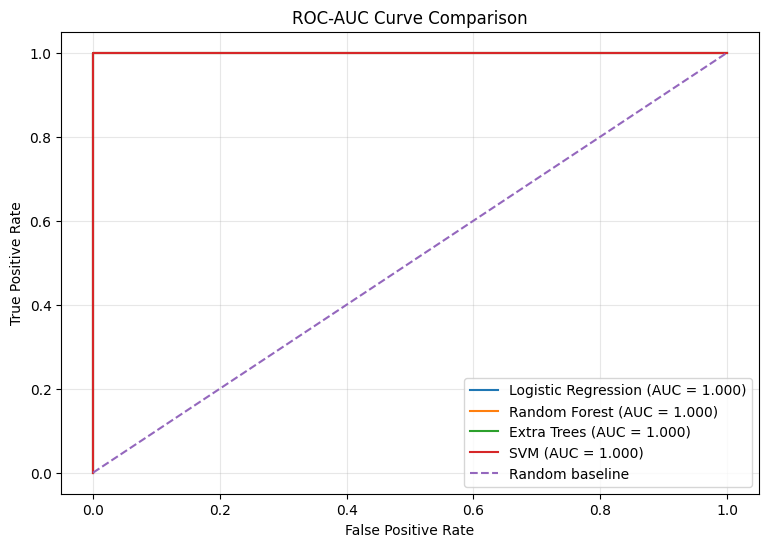

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, search in searches.items():
    model = search.best_estimator_
    probabilities = model.predict_proba(X_test)[:, 1]

    positive_label = model.classes_[1]
    fpr, tpr, _ = roc_curve(
        y_test, probabilities,
        pos_label=positive_label
    )

    auc = roc_auc_score(
        (y_test == positive_label).astype(int),
        probabilities
    )

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Best Model: Logistic Regression

Best Parameters:
{'classifier__C': 0.1}

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



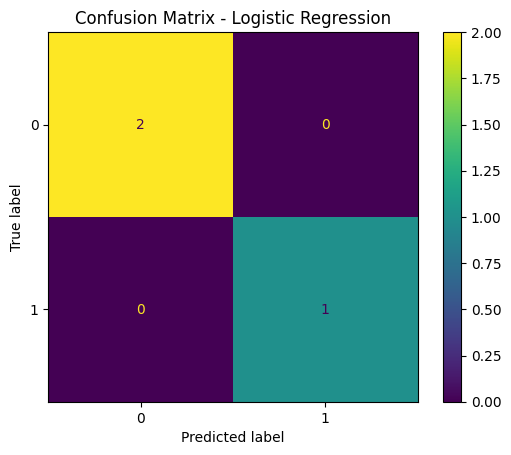

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay, classification_report

champion_name = comparison.iloc[0]["Model"]
champion_model = searches[champion_name].best_estimator_

print("Best Model:", champion_name)
print("\nBest Parameters:")
print(searches[champion_name].best_params_)

predictions = champion_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test, predictions, zero_division=0
))

ConfusionMatrixDisplay.from_estimator(
    champion_model, X_test, y_test
)
plt.title(f"Confusion Matrix - {champion_name}")
plt.show()


In [ ]:

import joblib
from google.colab import files

joblib.dump(champion_model, "customer_churn_champion.joblib")
comparison.to_csv("model_comparison.csv", index=False)

files.download("customer_churn_champion.joblib")
files.download("model_comparison.csv")

print("Model and comparison table saved successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model and comparison table saved successfully!


In [ ]:

import os
import joblib

print("Model file exists:",
      os.path.exists("customer_churn_champion.joblib"))

print("Comparison file exists:",
      os.path.exists("model_comparison.csv"))

print("\nFinal Model Comparison:")
display(comparison)

print("\nChampion Model:", champion_name)
print("Best CV ROC-AUC:",
      round(searches[champion_name].best_score_, 4))


Model file exists: True
Comparison file exists: True

Final Model Comparison:


,Model,CV ROC-AUC,Test Accuracy,Precision,Recall,F1-Score,Test ROC-AUC
0,Logistic Regression,NaN,1.0,1.0,1.0,1.0,1.0
1,Random Forest,NaN,1.0,1.0,1.0,1.0,1.0
2,Extra Trees,NaN,1.0,1.0,1.0,1.0,1.0
3,SVM,NaN,1.0,1.0,1.0,1.0,1.0



Champion Model: Logistic Regression
Best CV ROC-AUC: nan
